# 2. Baselines
Simple models first. Every number comes from the same evaluator: MAP@12 over the **whole catalogue**,
for customers who bought something in the test week. Hyper-parameters are chosen on the *validation*
week; the test week is only used to report.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from hmrec import workspace
pd.set_option("display.width", 140); plt.rcParams["figure.dpi"] = 110

# 10% of customers, seeded. Falls back to a tiny synthetic fixture (with a warning) if the
# real data has not been downloaded yet.
W = workspace.setup(sample_frac=0.10, seed=0)
hm, split = W.hm, W.split
if W.synthetic:
    print("*** SYNTHETIC DATA - numbers below are not H&M results ***")

In [2]:
from hmrec import models as Mo
from hmrec.evaluate import paired_bootstrap
grids = {
    "popularity": [Mo.Popularity(d) for d in (7, 14, 28)],
    "repurchase": [Mo.Repurchase(h) for h in (7, 14, 28, 56)],
    "age-popularity": [Mo.AgePopularity(d) for d in (7, 14)],
    "co-purchase": [Mo.CoPurchase(days=d) for d in (28, 56)],
    "als": [Mo.ALS(factors=f, days=(26 * 7)) for f in (32, 64)],
}
val_rows = []
for family, models in grids.items():
    for m in models:
        m.fit(W.ctx_train)
        val_rows.append((family, m.name, W.ev_val.evaluate(m).summary["map@12"]))
val = pd.DataFrame(val_rows, columns=["family", "config", "val_map@12"])
val.sort_values("val_map@12", ascending=False)

,family,config,val_map@12
3,repurchase,repurchase-hl7d,0.027171
4,repurchase,repurchase-hl14d,0.027009
5,repurchase,repurchase-hl28d,0.026036
6,repurchase,repurchase-hl56d,0.024513
12,als,als-64f,0.008418
9,co-purchase,co-purchase-28d,0.008051
10,co-purchase,co-purchase-56d,0.007527
11,als,als-32f,0.006865
7,age-popularity,age-popularity-7d,0.006761
8,age-popularity,age-popularity-14d,0.006556


### Pick the best config per family on validation, report on test

In [3]:
best = val.loc[val.groupby("family")["val_map@12"].idxmax()]
factory = {m.name: m for ms in grids.values() for m in ms}
results = {}
for _, row in best.iterrows():
    m = type(factory[row.config])  # refit the chosen config on train+val
    model = factory[row.config].fit(W.ctx_fit)
    results[row.family] = W.ev_test.evaluate(model, row.family)
table = pd.DataFrame({k: v.summary for k, v in results.items()}).T
ci = pd.Series({k: v.ci["map@12"] for k, v in results.items()})
table["map@12 95% CI"] = ci.map(lambda x: f"[{x[0]:.4f}, {x[1]:.4f}]")
table[["map@12", "map@12 95% CI", "recall@12", "recall@100", "coverage", "novelty", "head_share"]].sort_values("map@12", ascending=False).round(4)

,map@12,map@12 95% CI,recall@12,recall@100,coverage,novelty,head_share
repurchase,0.0273,"[0.0239, 0.0307]",0.0464,0.0502,0.1429,10.4749,0.2700
als,0.0092,"[0.0076, 0.0108]",0.0210,0.0664,0.0214,8.3077,0.8920
age-popularity,0.0082,"[0.0068, 0.0098]",0.0264,0.1092,0.0006,9.5143,0.3409
popularity,0.0081,"[0.0067, 0.0098]",0.0239,0.1108,0.0001,9.3073,0.3333
co-purchase,0.0069,"[0.0056, 0.0085]",0.0175,0.0385,0.0802,12.0122,0.0813


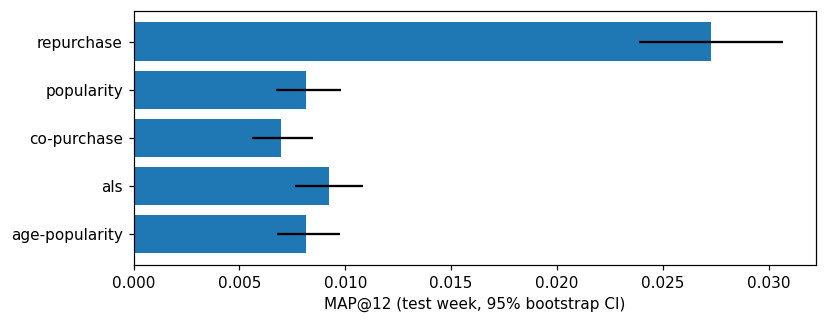

In [4]:
names = list(results)
fig, ax = plt.subplots(figsize=(8, 3))
means = [results[n].summary["map@12"] for n in names]
errs = [[results[n].summary["map@12"] - results[n].ci["map@12"][0] for n in names],
        [results[n].ci["map@12"][1] - results[n].summary["map@12"] for n in names]]
ax.barh(names, means, xerr=errs); ax.set_xlabel("MAP@12 (test week, 95% bootstrap CI)"); plt.show()

**Reading:** repurchase usually beats global popularity by a wide margin on this kind of
data. Is the best simple model *significantly* better than the runner-up? Check with a paired bootstrap:

In [5]:
ranked_models = sorted(results.values(), key=lambda r: -r.summary["map@12"])
a, b = ranked_models[0], ranked_models[1]
print(a.model, "vs", b.model, paired_bootstrap(a.per_user["map@12"], b.per_user["map@12"]))

repurchase vs als {'diff': 0.018051241475237907, 'lo': 0.014847309671281077, 'hi': 0.021394619468116452, 'significant': True}
